<a href="https://colab.research.google.com/github/AnshuAnshu01/Data_Analytics_Python/blob/main/Patient_Records/Patient_Records.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [59]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df=pd.read_csv('patient_records.csv')

## Basic & Medium Questions

### Question 1: How many patients are recorded in this dataset, and what are the names of the columns?

In [60]:
# Write your code for Question 1 here
df.info()
df.shape

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 50 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   patient_id              100000 non-null  object 
 1   first_name              100000 non-null  object 
 2   last_name               100000 non-null  object 
 3   gender                  100000 non-null  object 
 4   date_of_birth           100000 non-null  object 
 5   age                     100000 non-null  int64  
 6   blood_group             100000 non-null  object 
 7   preferred_language      100000 non-null  object 
 8   city                    100000 non-null  object 
 9   state                   100000 non-null  object 
 10  insurance_provider      100000 non-null  object 
 11  insurance_plan          100000 non-null  object 
 12  admission_date          100000 non-null  object 
 13  discharge_date          100000 non-null  object 
 14  length_of_stay_days  

(100000, 50)

In [61]:
df['date_of_birth'] = pd.to_datetime(df['date_of_birth'])

In [62]:
df['date_of_birth'].dtype

dtype('<M8[ns]')

### Question 2: Are there any missing/null values in any of the columns? If so, which ones and how many?

In [63]:
# Write your code for Question 2 here

df.isnull().sum()


,0
patient_id,0
first_name,0
last_name,0
gender,0
date_of_birth,0
age,0
blood_group,0
preferred_language,0
city,0
state,0


### Question 3: What is the average, median, minimum, and maximum age of the patients?

In [64]:
# Write your code for Question 3 here
print(df['age'].describe())
print(df['age'].mean())
print(df['age'].median())
print(df['age'].min())
print(df['age'].max())


count    100000.000000
mean         44.739350
std          19.472329
min           1.000000
25%          30.000000
50%          42.000000
75%          56.000000
max         100.000000
Name: age, dtype: float64
44.73935
42.0
1
100


### Question 4: What is the overall distribution of patient gender (or similar categorical columns)?

In [65]:
# Write your code for Question 4 here
df['gender'].value_counts()



,count
gender,
Male,50229
Female,49282
Other,489


### Question 5: Slice the dataset to get only patients who are older than 60 years.

In [66]:
# Write your code for Question 5 here
print(df[df['age']>60].head())
df[df['age'] > 60].shape[0]

   patient_id first_name last_name  gender date_of_birth  age blood_group  \
2   PT0000003       Riya      Iyer  Female    1939-01-08   87          A+   
4   PT0000005      Swati     Pawar  Female    1947-11-04   78          O+   
5   PT0000006      Tanvi   Trivedi  Female    1961-03-24   65         AB+   
8   PT0000009     Aditya    Shinde    Male    1938-12-24   87          B-   
16  PT0000017      Vijay     Patel    Male    1937-07-28   89          O+   

   preferred_language        city        state  ... primary_medication  \
2               Tamil  Coimbatore   Tamil Nadu  ...         Diclofenac   
4             Marathi      Mumbai  Maharashtra  ...         Amlodipine   
5            Gujarati       Surat      Gujarat  ...          Metformin   
8             Marathi      Mumbai  Maharashtra  ...       Atorvastatin   
16           Gujarati   Ahmedabad      Gujarat  ...         Amlodipine   

   lab_tests_ordered total_bill_inr insurance_covered_inr  patient_paid_inr  \
2            

19860

### Question 6: Retrieve the records of patients from index 50 to 100 with only their patient identifier, age, and primary diagnosis.

In [67]:
# Write your code for Question 6 here
df.loc[50:100,['patient_id','age','primary_diagnosis']]


,patient_id,age,primary_diagnosis
50,PT0000051,28,Pneumonia
51,PT0000052,44,Pneumonia
52,PT0000053,30,COPD
53,PT0000054,13,Acute Appendicitis
54,PT0000055,70,Essential Hypertension
55,PT0000056,49,Type 2 Diabetes Mellitus
56,PT0000057,43,Oral Cavity Cancer
57,PT0000058,21,Viral Fever / Influenza
58,PT0000059,33,Essential Hypertension
59,PT0000060,77,Oral Cavity Cancer


### Question 7: How many unique diagnoses or patient classes exist in the dataset?

In [68]:
# Write your code for Question 7 here
df['primary_diagnosis'].nunique()


38

### Question 8: Create a new column calculating the Patient BMI if weight and height columns are present (or write a function to categorize age into 'Youth', 'Adult', 'Senior').

In [69]:
# Write your code for Question 8 here
df['Bmi']=df['weight_kg']/(df['height_cm']/100)**2
print(df.head())
df['age_group']=pd.cut(df['age'],bins=[0,18,65,100],labels=['Youth','Adult','Senior'])
print(df.head())


  patient_id first_name last_name  gender date_of_birth  age blood_group  \
0  PT0000001    Sravani    Kapoor  Female    2000-09-03   26          O+   
1  PT0000002      Swati  Banerjee  Female    2003-03-22   23          A+   
2  PT0000003       Riya      Iyer  Female    1939-01-08   87          A+   
3  PT0000004     Balaji  Varghese    Male    1985-03-16   41         AB+   
4  PT0000005      Swati     Pawar  Female    1947-11-04   78          O+   

  preferred_language        city        state  ... lab_tests_ordered  \
0              Hindi       Patna        Bihar  ...                 7   
1            Bengali     Kolkata  West Bengal  ...                 3   
2              Tamil  Coimbatore   Tamil Nadu  ...                19   
3          Malayalam       Kochi       Kerala  ...                 5   
4            Marathi      Mumbai  Maharashtra  ...                 3   

  total_bill_inr insurance_covered_inr patient_paid_inr  payment_status  \
0       13348.10               8399

### Question 9: What is the most common primary medical condition or reason for admission?

In [70]:
# Write your code for Question 9 here
df['primary_diagnosis'].value_counts()

,count
primary_diagnosis,
Essential Hypertension,9213
Type 2 Diabetes Mellitus,8088
Viral Fever / Influenza,6855
Pneumonia,4270
Iron Deficiency Anemia,3898
Coronary Artery Disease,3833
Asthma,3561
Acute Gastroenteritis,3531
Dengue Fever,3514


### Question 10: Calculate the standard deviation and variance of a key numerical health metric (e.g., blood pressure, cholesterol, or blood sugar).

In [71]:
print(df['systolic_bp'].std())
print(df['systolic_bp'].var())

print(df['total_cholesterol_mgdl'].std())
print(df['total_cholesterol_mgdl'].var())

print(df['blood_glucose_mgdl'].std())
print(df['blood_glucose_mgdl'].var())

17.571477642115767
308.7568265273743
34.34908027791246
1179.859315938475
55.70727567560849
3103.3005631982414


### Question 11: Group the dataset by gender/sex and find the mean value of all numerical vitals.

In [72]:
df.groupby('gender').mean(numeric_only=True)




,age,length_of_stay_days,comorbidity_count,icu_admission,height_cm,weight_kg,bmi,systolic_bp,diastolic_bp,heart_rate_bpm,...,hemoglobin_gdl,creatinine_mgdl,lab_tests_ordered,total_bill_inr,insurance_covered_inr,patient_paid_inr,readmitted_30d,risk_score,patient_satisfaction,Bmi
gender,,,,,,,,,,,,,,,,,,,,,
Female,44.774015,2.315389,1.321700,0.037884,152.287825,57.234087,24.548403,124.895682,79.454365,81.040928,...,11.573649,0.967166,8.093888,48134.904252,28602.211492,14590.086486,0.083418,17.422345,3.912828,24.548409
Male,44.697127,2.315415,1.328276,0.035955,164.641030,67.114617,24.567099,124.807920,79.364013,81.397161,...,13.360387,1.120583,8.107966,46625.529639,27837.981898,13978.791419,0.082801,17.677716,3.914850,24.567177
Other,45.582822,2.257669,1.351738,0.036810,165.204908,67.030266,24.407566,125.278119,80.087935,82.157464,...,13.308577,0.981882,8.118609,48091.907853,29978.913988,13895.033190,0.073620,17.609407,3.905930,24.408993


preferred_language
Hindi        27076
Marathi      17846
Telugu       13924
Tamil         9312
Gujarati      7890
Kannada       7830
Bengali       6905
Malayalam     5327
Assamese      1951
Punjabi       1939
Name: count, dtype: int64


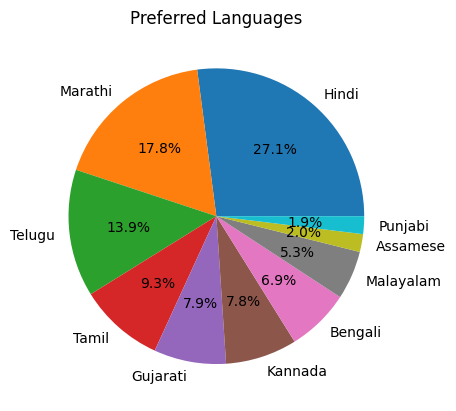

In [73]:
l=df['preferred_language'].value_counts()
print(l)
plt.pie(l,labels=l.index,autopct='%1.1f%%')
plt.title('Preferred Languages')
plt.show()

### Question 12: What is the average length of stay (or hospital duration) for patients across different admission types?

In [136]:

avg_stay = df.groupby('admission_type')['length_of_stay_days'].mean()

print(avg_stay)

admission_type
Elective      2.931670
Emergency     3.545515
Outpatient    0.000000
Urgent        2.895530
Name: length_of_stay_days, dtype: float64


### Question 13: Filter the patients who have above-average values for a key health risk indicator (e.g., cholesterol level > average cholesterol).

In [74]:
df.groupby('admission_type')['length_of_stay_days'].mean()

,length_of_stay_days
admission_type,
Elective,2.931670
Emergency,3.545515
Outpatient,0.000000
Urgent,2.895530


### Question 14: Identify the top 5 most expensive treatments or highest billing amounts in the dataset.

In [75]:
df.nlargest(5, 'total_bill_inr')


,patient_id,first_name,last_name,gender,date_of_birth,age,blood_group,preferred_language,city,state,...,total_bill_inr,insurance_covered_inr,patient_paid_inr,payment_status,discharge_disposition,readmitted_30d,risk_score,patient_satisfaction,Bmi,age_group
41264,PT0041265,Deepa,Chowdary,Female,1977-08-29,49,A+,Telugu,Vijayawada,Andhra Pradesh,...,997673.76,844400.24,153273.52,Paid,Home,0,44,4,24.442956,Adult
21553,PT0021554,Prakash,Gaikwad,Male,1953-03-17,73,B+,Marathi,Mumbai,Maharashtra,...,945730.98,729873.30,215857.68,Paid,Home,0,43,4,27.786772,Senior
22990,PT0022991,Simran,Mirza,Female,2002-09-11,24,O+,Marathi,Pune,Maharashtra,...,934406.75,561504.44,176405.14,Partially Paid,Home Health Care,0,35,5,29.496771,Adult
55078,PT0055079,Sandeep,Ahmed,Male,2000-05-21,26,A+,Telugu,Hyderabad,Telangana,...,899609.20,0.00,899609.20,Paid,Home,0,28,3,17.511898,Adult
37897,PT0037898,Rohan,Natarajan,Male,1973-04-05,53,A+,Tamil,Chennai,Tamil Nadu,...,842847.60,775779.77,67067.83,Paid,Home,0,42,5,18.842428,Adult


### Question 15: Pivot the data to show the average billing amount grouped by both diagnosis and insurance provider.

In [76]:
pd.pivot_table(
    df,
    values='total_bill_inr',
    index='primary_diagnosis',
    columns='insurance_provider',
    aggfunc='mean'
)


insurance_provider,Ayushman Bharat (PM-JAY),CGHS,Care Health,ESIC,HDFC ERGO,ICICI Lombard,Niva Bupa,Self-Pay,Star Health
primary_diagnosis,,,,,,,,,
Acute Appendicitis,93827.577152,97637.782020,96713.950839,88232.530603,95866.065989,97128.059056,98630.565851,93717.994383,92718.649538
Acute Gastroenteritis,22286.039209,22274.937018,21466.003702,21982.730239,21830.831401,19771.193746,22066.042511,20685.339463,21228.539877
Asthma,20733.383458,21192.293873,19699.384664,19094.198930,20837.487961,21022.414577,20495.490240,21523.903129,21390.527453
Atrial Fibrillation,81636.181466,95921.090714,93427.531311,98909.911746,81276.970978,77069.116857,78363.012105,79882.286542,80526.360000
Breast Cancer,95028.297098,82739.849655,86400.458605,92380.947209,98429.510909,73766.604340,103292.819024,85586.007054,78045.613704
COPD,33702.813667,35355.847077,33543.901063,32748.687238,32455.229526,32449.745233,33315.810818,33569.634249,33754.074675
Cervical Cancer,88424.200267,96956.366154,74253.110833,81095.089091,79960.347619,99429.271818,101069.435789,81719.420299,86190.338235
Cholelithiasis,82825.841734,90335.094394,89123.861978,82836.990976,86752.687170,88387.849773,73492.437128,87055.731526,84837.289774
Chronic Kidney Disease,87569.441093,89749.970960,89169.012174,91523.882208,85934.825671,91041.465089,88060.247805,86416.944928,86259.511698


### Question 16: How many patients were admitted or recorded in each month/year (requires datetime parsing)?

In [77]:
print(df['admission_date'].dtype)


object


In [78]:
df['admission_date'] = pd.to_datetime(df['admission_date'])

In [79]:
print(df['admission_date'].dtype)

datetime64[ns]


In [80]:
yearly_patients = df.groupby(
    df['admission_date'].dt.year
)['patient_id'].count()

print(yearly_patients)

monthly_patients = df.groupby(
    df['admission_date'].dt.to_period('M')
).size().reset_index(name='patient_count')

print(monthly_patients)

admission_date
2023     5770
2024    33507
2025    33071
2026    27652
Name: patient_id, dtype: int64
   admission_date  patient_count
0         2023-11           2813
1         2023-12           2957
2         2024-01           2868
3         2024-02           2667
4         2024-03           2870
5         2024-04           2732
6         2024-05           2859
7         2024-06           2727
8         2024-07           2964
9         2024-08           2730
10        2024-09           2625
11        2024-10           2879
12        2024-11           2716
13        2024-12           2870
14        2025-01           2740
15        2025-02           2530
16        2025-03           2937
17        2025-04           2730
18        2025-05           2920
19        2025-06           2661
20        2025-07           2756
21        2025-08           2750
22        2025-09           2766
23        2025-10           2827
24        2025-11           2765
25        2025-12           2689
26     

### Question 17: Find and replace any missing numeric values with the median of their respective columns.

In [81]:
df.info()
df.fillna(df.median(numeric_only=True)).info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 52 columns):
 #   Column                  Non-Null Count   Dtype         
---  ------                  --------------   -----         
 0   patient_id              100000 non-null  object        
 1   first_name              100000 non-null  object        
 2   last_name               100000 non-null  object        
 3   gender                  100000 non-null  object        
 4   date_of_birth           100000 non-null  datetime64[ns]
 5   age                     100000 non-null  int64         
 6   blood_group             100000 non-null  object        
 7   preferred_language      100000 non-null  object        
 8   city                    100000 non-null  object        
 9   state                   100000 non-null  object        
 10  insurance_provider      100000 non-null  object        
 11  insurance_plan          100000 non-null  object        
 12  admission_date          100000 

### Question 18: Detect outliers in a critical vitals column using the IQR (Interquartile Range) method.

In [82]:
Q1 = df['systolic_bp'].quantile(0.25)
Q3 = df['systolic_bp'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['systolic_bp'] < lower_bound) |
              (df['systolic_bp'] > upper_bound)]

outliers.count()


,0
patient_id,2851
first_name,2851
last_name,2851
gender,2851
date_of_birth,2851
age,2851
blood_group,2851
preferred_language,2851
city,2851
state,2851


### Question 19: What percentage of patients returned for a readmission (if a readmission column exists)?

In [83]:
(df['readmitted_30d'].mean() * 100)


np.float64(8.306)

### Question 20: Merge or join this dataset with a dummy dictionary of Doctor IDs to doctor specialty names.

In [84]:
doctor_dict = {
    'Dr. Smith': 'Cardiology',
    'Dr. John': 'Neurology',
    'Dr. David': 'Orthopedics'
}

df['doctor_specialty'] = df['attending_physician'].map(doctor_dict)

df.head()


,patient_id,first_name,last_name,gender,date_of_birth,age,blood_group,preferred_language,city,state,...,insurance_covered_inr,patient_paid_inr,payment_status,discharge_disposition,readmitted_30d,risk_score,patient_satisfaction,Bmi,age_group,doctor_specialty
0,PT0000001,Sravani,Kapoor,Female,2000-09-03,26,O+,Hindi,Patna,Bihar,...,8399.35,4948.75,Paid,Left Against Medical Advice,0,14,3,34.422058,Adult,NaN
1,PT0000002,Swati,Banerjee,Female,2003-03-22,23,A+,Bengali,Kolkata,West Bengal,...,14303.04,2275.28,Paid,Home,0,4,4,36.980316,Adult,NaN
2,PT0000003,Riya,Iyer,Female,1939-01-08,87,A+,Tamil,Coimbatore,Tamil Nadu,...,0.00,34004.35,Paid,Home,1,43,4,22.995263,Senior,NaN
3,PT0000004,Balaji,Varghese,Male,1985-03-16,41,AB+,Malayalam,Kochi,Kerala,...,120264.20,12698.83,Paid,Home,0,10,4,21.421712,Adult,NaN
4,PT0000005,Swati,Pawar,Female,1947-11-04,78,O+,Marathi,Mumbai,Maharashtra,...,8206.91,2591.32,Paid,Home,0,24,4,24.222860,Senior,NaN


**Duplicated**

In [85]:
df[df.duplicated()]

,patient_id,first_name,last_name,gender,date_of_birth,age,blood_group,preferred_language,city,state,...,insurance_covered_inr,patient_paid_inr,payment_status,discharge_disposition,readmitted_30d,risk_score,patient_satisfaction,Bmi,age_group,doctor_specialty


## Part 2: Visualization Questions

### Question 21: Plot a histogram with a KDE (Kernel Density Estimate) curve showing the distribution of patient ages.

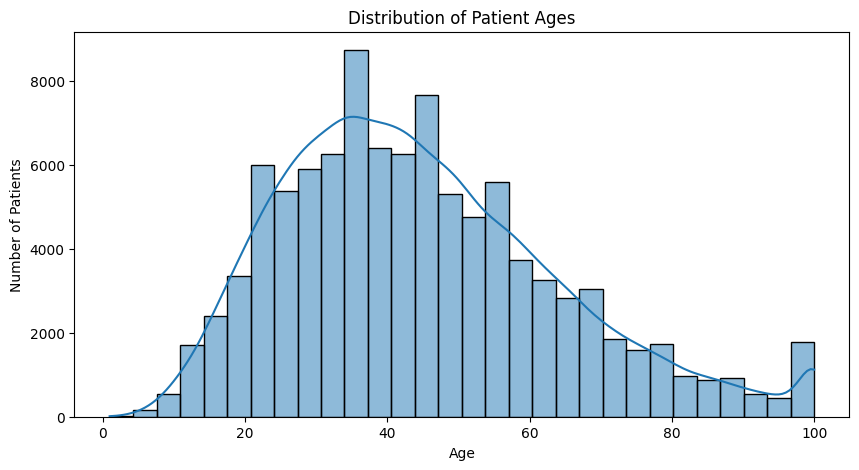

In [135]:
plt.figure(figsize=(10, 5))

sns.histplot(df['age'].dropna(), bins=30, kde=True)

plt.title("Distribution of Patient Ages")
plt.xlabel("Age")
plt.ylabel("Number of Patients")

plt.show()

### Question 22: Create a bar chart showing the count of patients across different departments or diagnoses, sorted in descending order.

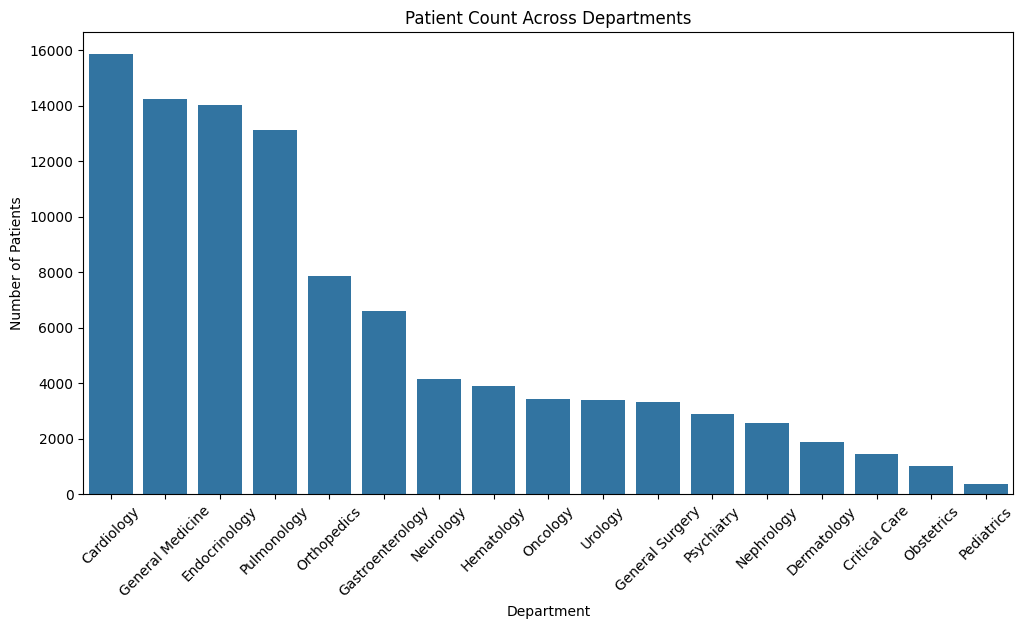

In [134]:
department_counts = df['department'].value_counts().sort_values(ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(x=department_counts.index, y=department_counts.values)

plt.title("Patient Count Across Departments")
plt.xlabel("Department")
plt.ylabel("Number of Patients")
plt.xticks(rotation=45)

plt.show()

### Question 23: Generate a box plot of billing amounts grouped by insurance provider to visually compare median costs and detect outliers.

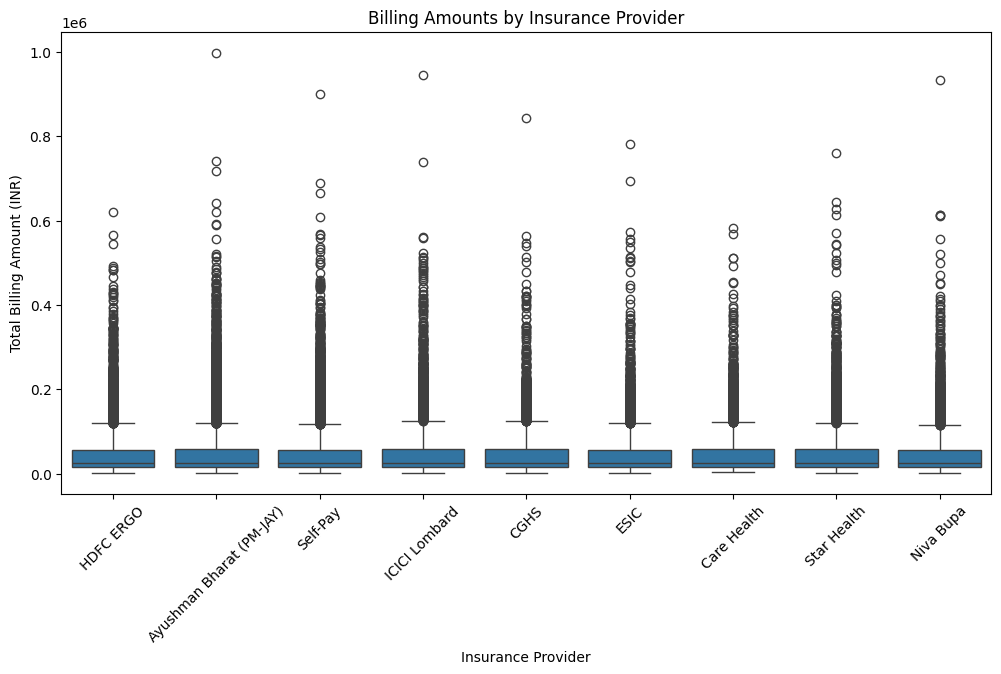

In [133]:
plt.figure(figsize=(12, 6))

sns.boxplot(data=df, x='insurance_provider', y='total_bill_inr')

plt.title("Billing Amounts by Insurance Provider")
plt.xlabel("Insurance Provider")
plt.ylabel("Total Billing Amount (INR)")
plt.xticks(rotation=45)

plt.show()

### Question 24: Draw a heatmap of the correlation matrix of numerical features with annotations turned on.

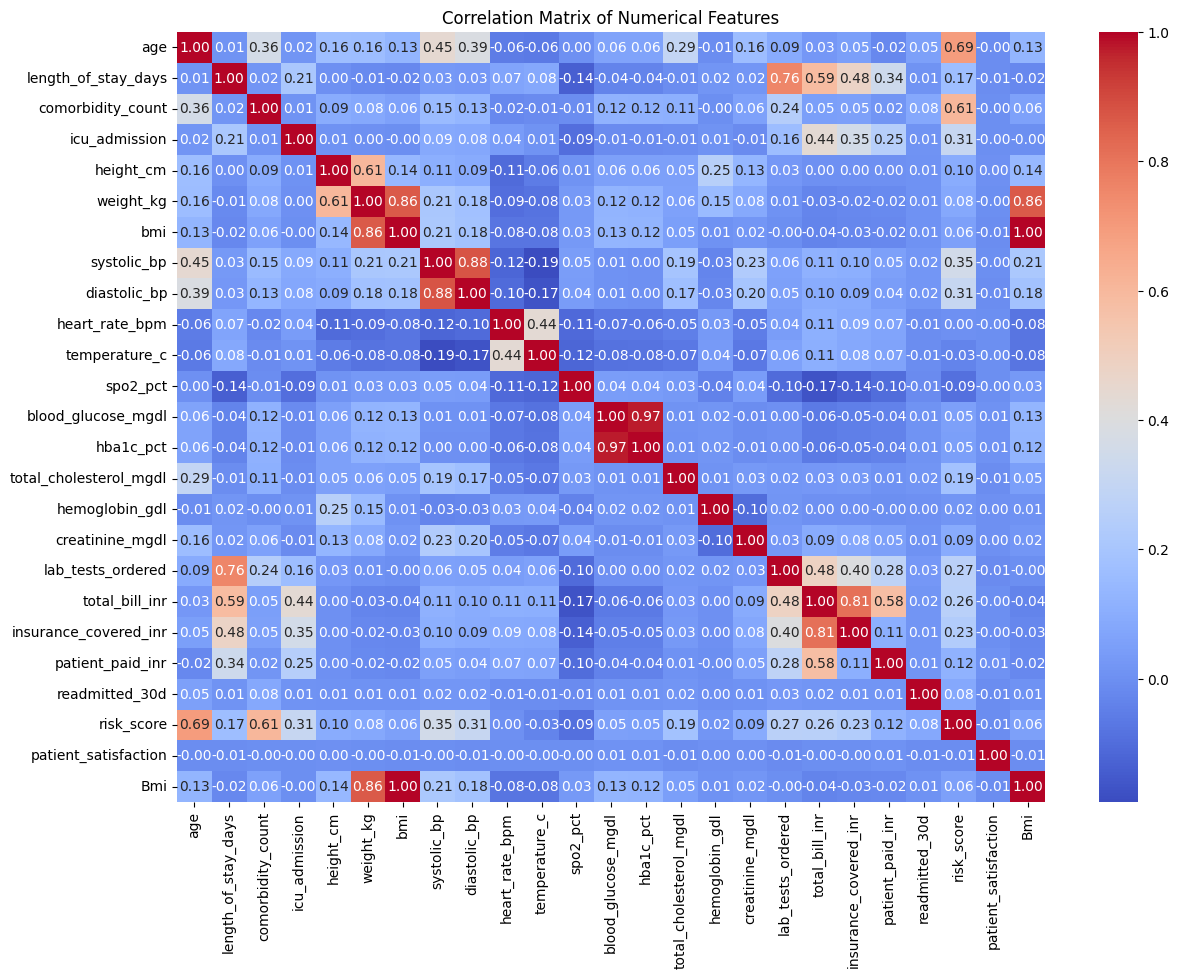

In [132]:
corr_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(14, 10))

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')

plt.title("Correlation Matrix of Numerical Features")
plt.show()

### Question 25: Create a scatter plot comparing two continuous variables (e.g., Age vs. Blood Pressure) with the data points color-coded by gender or health status.

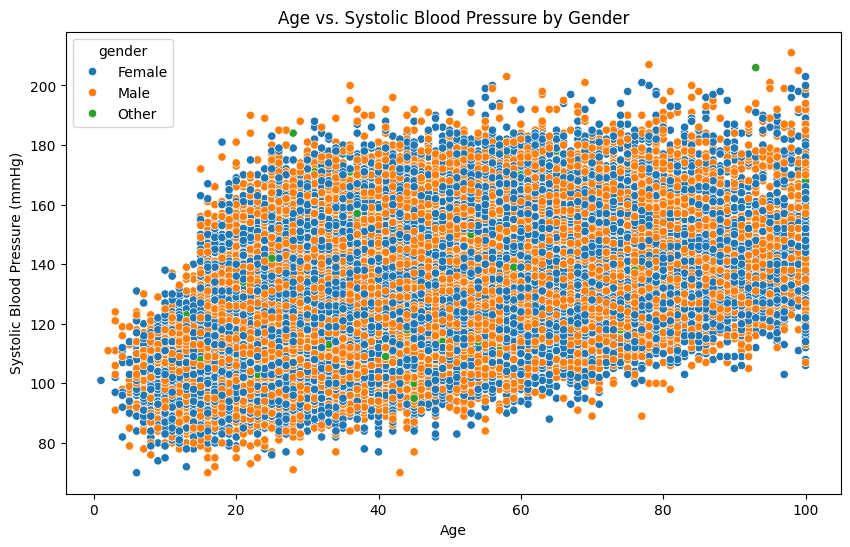

In [131]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='age',
    y='systolic_bp',
    hue='gender'
)

plt.title("Age vs. Systolic Blood Pressure by Gender")
plt.xlabel("Age")
plt.ylabel("Systolic Blood Pressure (mmHg)")
plt.show()

### Question 26: Use a Seaborn violin plot to visualize the distribution of length of stay across different admission types.

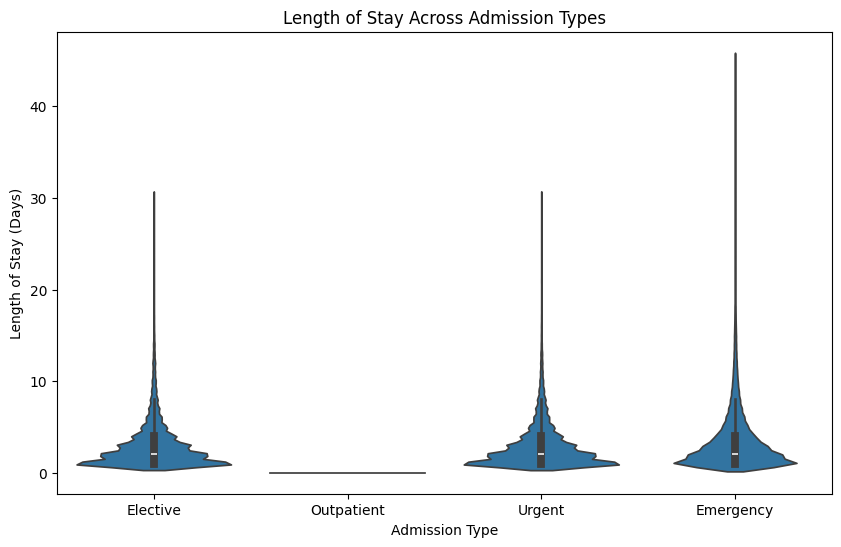

In [130]:
plt.figure(figsize=(10, 6))

sns.violinplot(
    data=df,
    x='admission_type',
    y='length_of_stay_days'
)

plt.title("Length of Stay Across Admission Types")
plt.xlabel("Admission Type")
plt.ylabel("Length of Stay (Days)")
plt.show()

### Question 27: Plot a line chart showing the monthly trend of patient admissions over time.

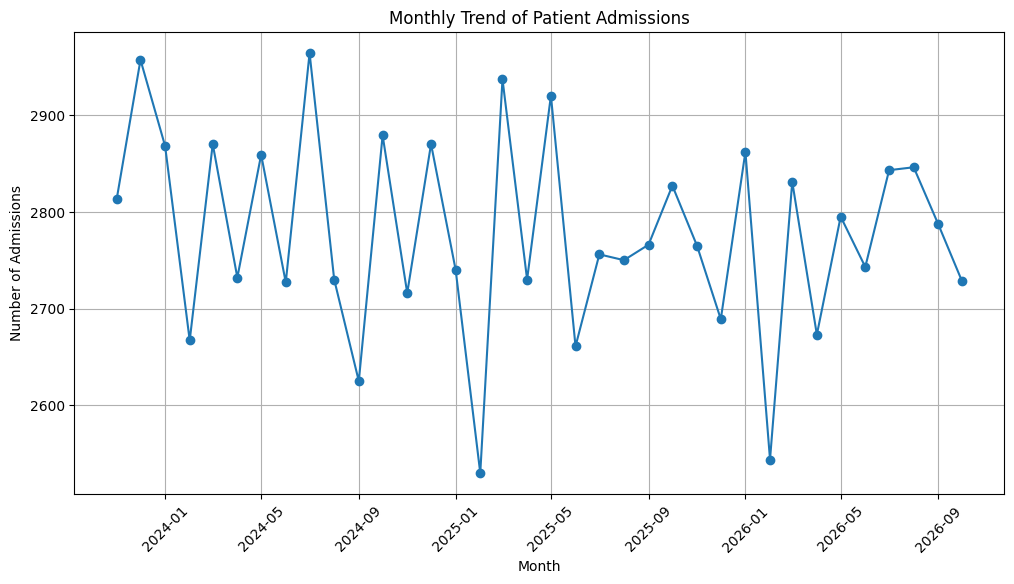

In [129]:
df['admission_date'] = pd.to_datetime(df['admission_date'])

monthly_admissions = df.groupby(
    df['admission_date'].dt.to_period('M')
).size()

monthly_admissions.index = monthly_admissions.index.to_timestamp()

plt.figure(figsize=(12, 6))

plt.plot(monthly_admissions.index, monthly_admissions.values, marker='o')

plt.title("Monthly Trend of Patient Admissions")
plt.xlabel("Month")
plt.ylabel("Number of Admissions")
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

### Question 28: Create a stacked bar chart showing the proportion of readmissions (Yes vs. No) within each diagnosis group.

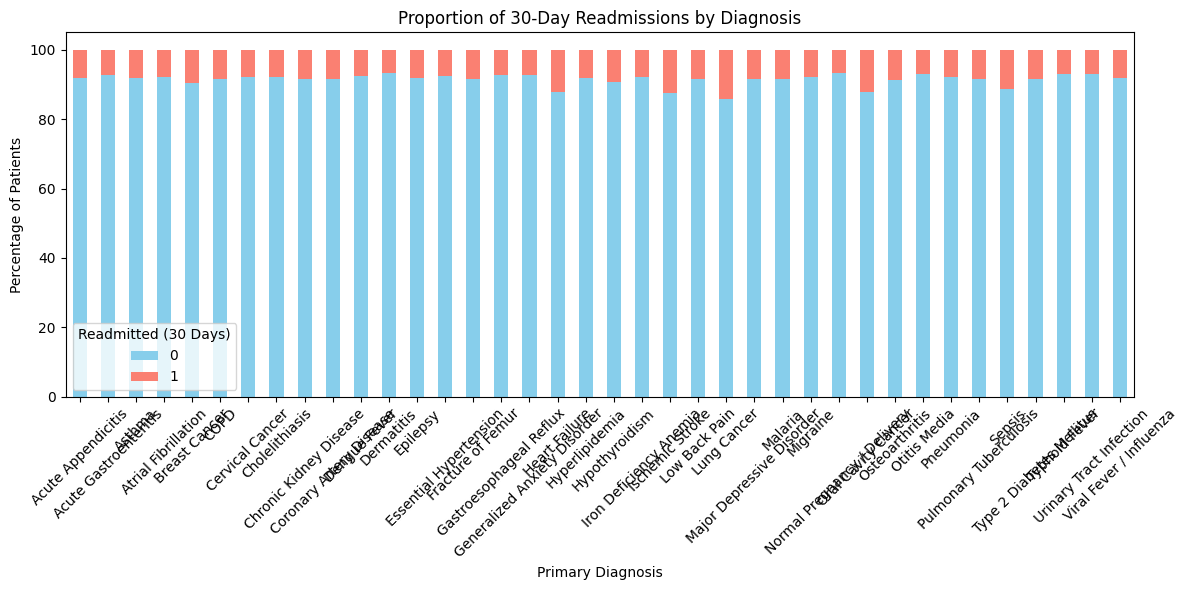

In [128]:
readmission_prop = pd.crosstab(
    df['primary_diagnosis'],
    df['readmitted_30d'],
    normalize='index'
) * 100

readmission_prop.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6),
    color=['skyblue', 'salmon']
)

plt.title("Proportion of 30-Day Readmissions by Diagnosis")
plt.xlabel("Primary Diagnosis")
plt.ylabel("Percentage of Patients")
plt.legend(title="Readmitted (30 Days)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

### Question 29: Plot a pairplot (`sns.pairplot`) of the key clinical metrics to explore pairwise relationships and distributions simultaneously.

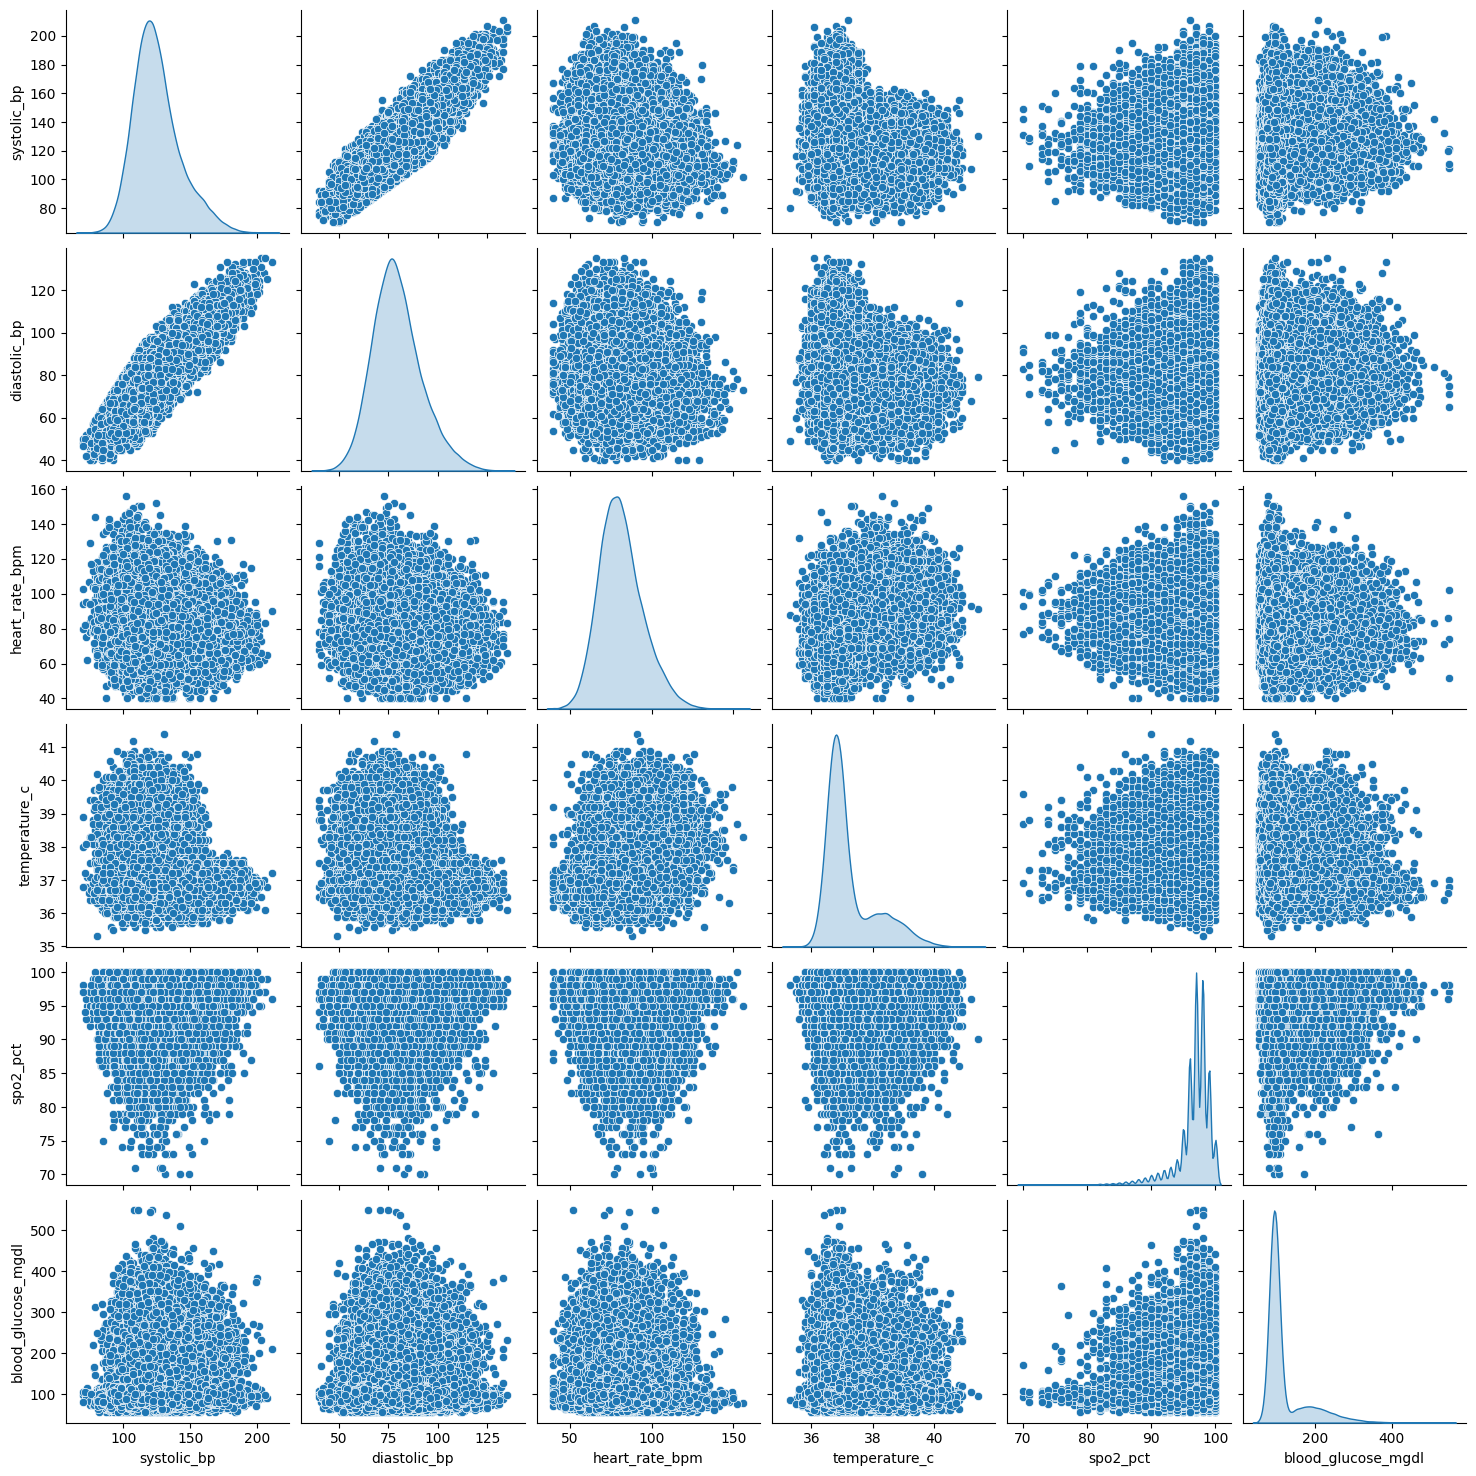

In [127]:
clinical_metrics = [
    'systolic_bp',
    'diastolic_bp',
    'heart_rate_bpm',
    'temperature_c',
    'spo2_pct',
    'blood_glucose_mgdl'
]

sns.pairplot(
    df[clinical_metrics].dropna(),
    diag_kind='kde'
)

plt.show()

### Question 30: Create a multi-plot grid (using Seaborn's `FacetGrid` or Matplotlib subplots) showing the distribution of vital signs compared side-by-side for different age groups.

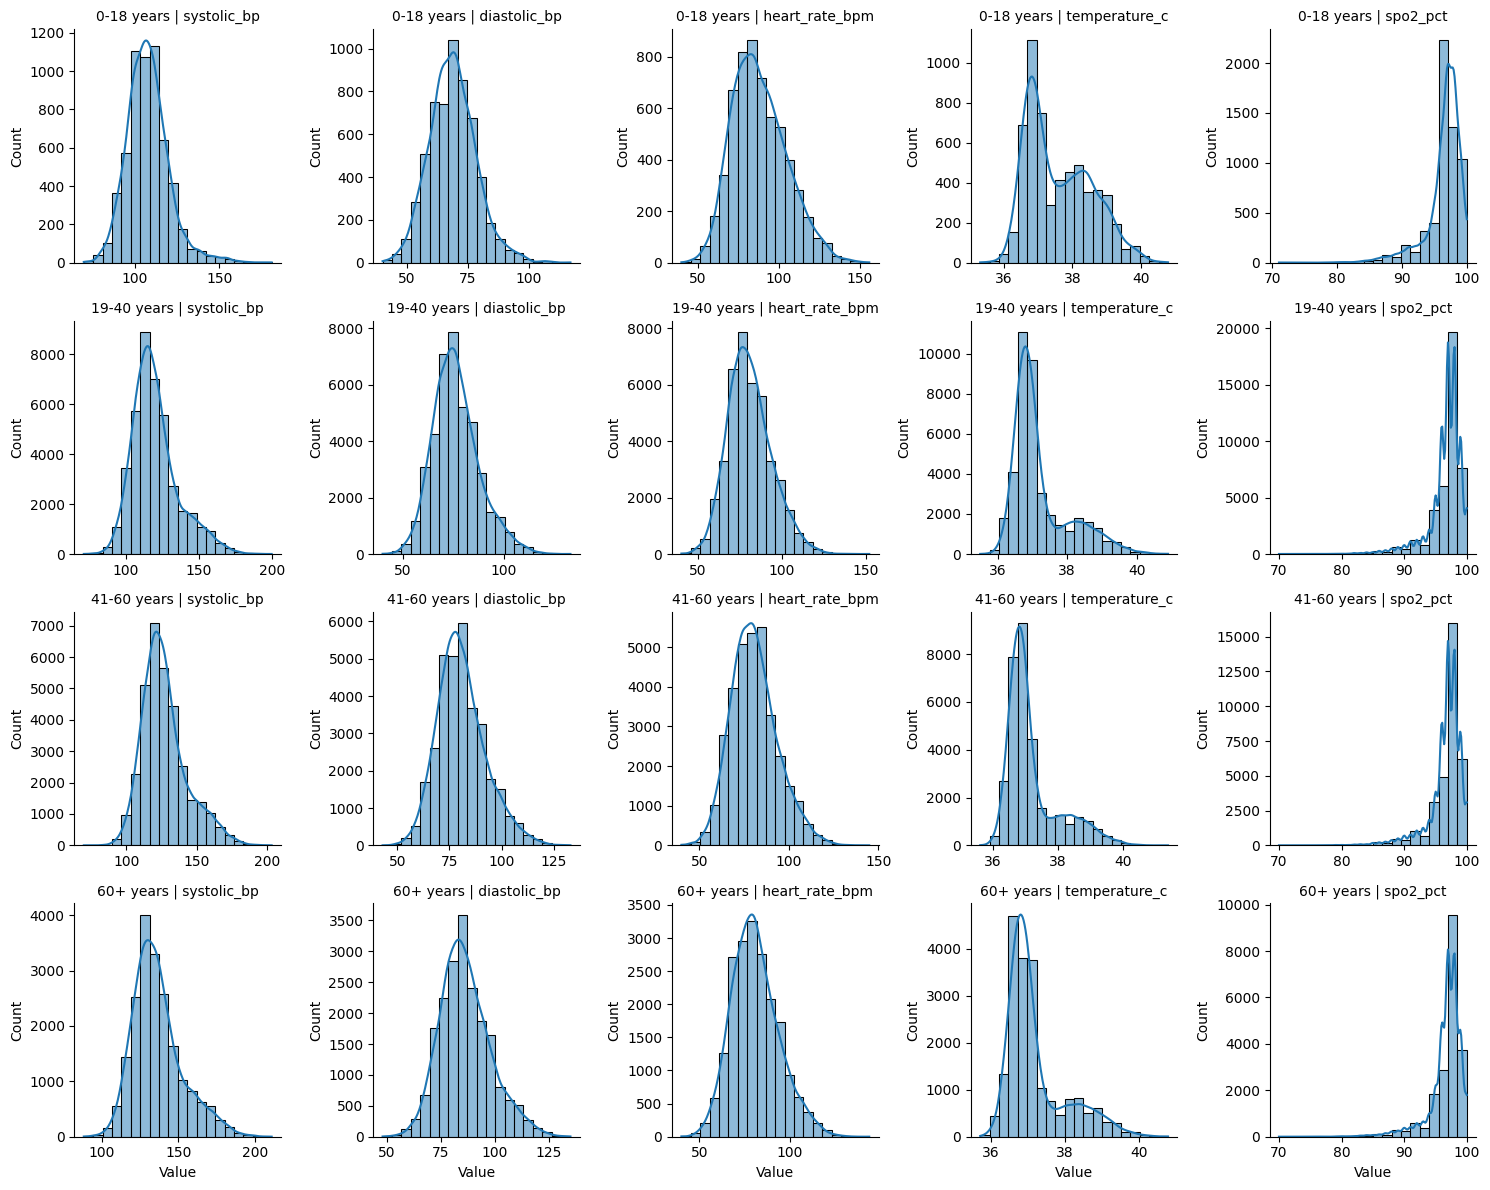

In [126]:
df['age_group'] = pd.cut(
    df['age'],
    bins=[0, 18, 40, 60, 100],
    labels=['0-18', '19-40', '41-60', '60+']
)

vital_signs = [
    'systolic_bp',
    'diastolic_bp',
    'heart_rate_bpm',
    'temperature_c',
    'spo2_pct'
]

vitals_df = df.melt(
    id_vars='age_group',
    value_vars=vital_signs,
    var_name='Vital Sign',
    value_name='Value'
)

g = sns.FacetGrid(
    vitals_df,
    col='Vital Sign',
    row='age_group',
    sharex=False,
    sharey=False,
    height=3
)

g.map_dataframe(sns.histplot, x='Value', bins=20, kde=True)

g.set_titles("{row_name} years | {col_name}")
g.tight_layout()

plt.show()

### Question 31: Single-Row Multi-Pie Comparison (Gender vs Admission Type)

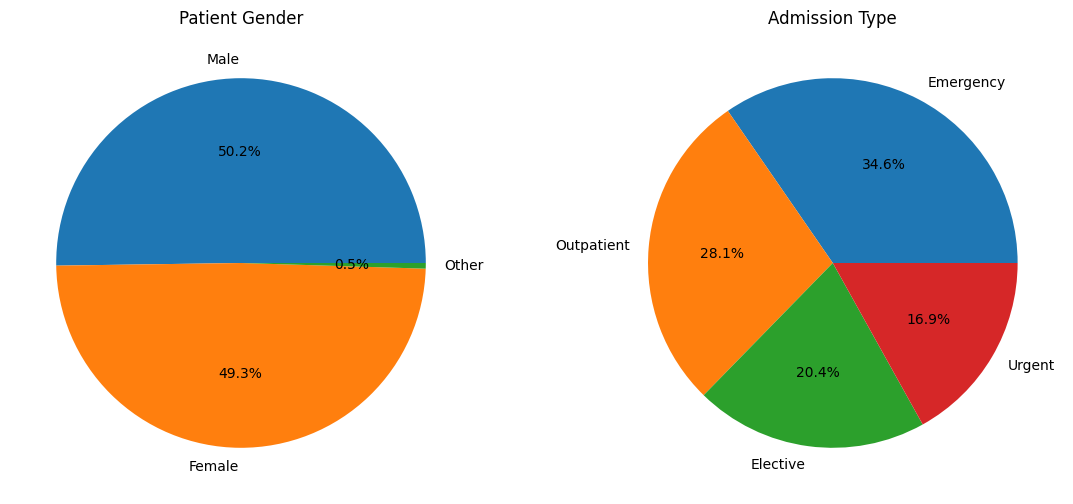

In [116]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

gender_counts = df['gender'].value_counts()
axes[0].pie(gender_counts, labels=gender_counts.index, autopct='%1.1f%%')
axes[0].set_title('Patient Gender')

admission_counts = df['admission_type'].value_counts()
axes[1].pie(admission_counts, labels=admission_counts.index, autopct='%1.1f%%')
axes[1].set_title('Admission Type')

plt.show()

### Question 32: Grouped Bar Chart (Average Length of Stay by Gender & Admission Type)

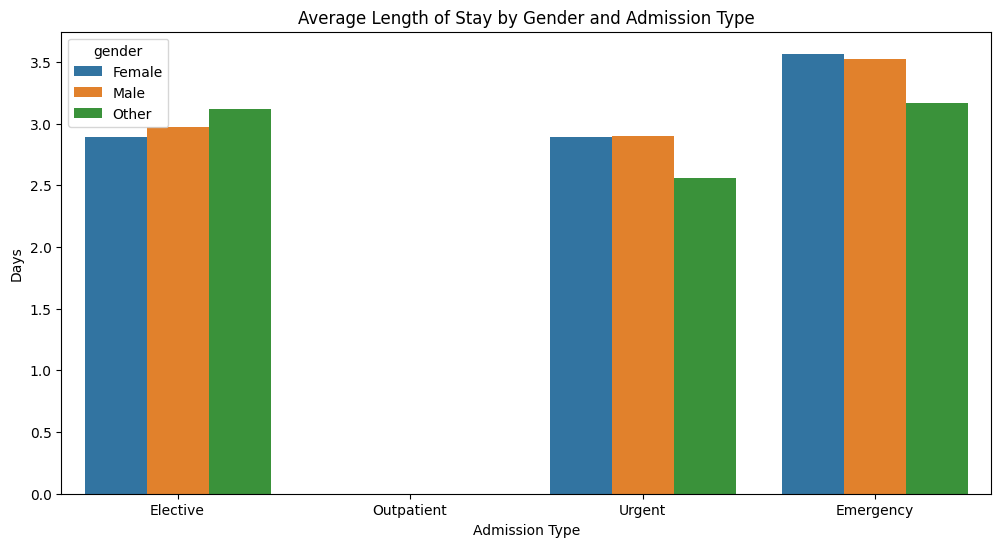

In [117]:
plt.figure(figsize=(12, 6))
sns.barplot(data=df, x='admission_type', y='length_of_stay_days', hue='gender', errorbar=None)
plt.title('Average Length of Stay by Gender and Admission Type')
plt.xlabel('Admission Type')
plt.ylabel('Days')
plt.show()

### Question 33: Single-Row Bar Comparison (Top Diagnoses: Under 40 vs Over 40)

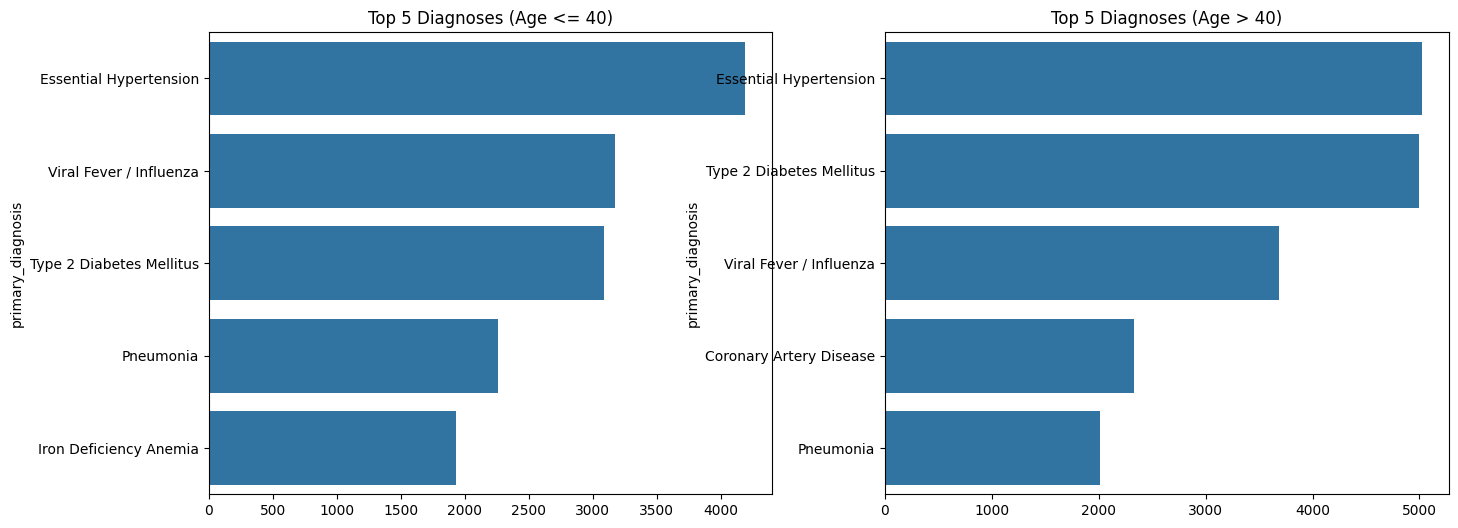

In [118]:
under_40 = df[df['age'] <= 40]['primary_diagnosis'].value_counts().head(5)
over_40 = df[df['age'] > 40]['primary_diagnosis'].value_counts().head(5)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(x=under_40.values, y=under_40.index, ax=axes[0])
axes[0].set_title('Top 5 Diagnoses (Age <= 40)')

sns.barplot(x=over_40.values, y=over_40.index, ax=axes[1])
axes[1].set_title('Top 5 Diagnoses (Age > 40)')

plt.show()

### Question 34: Dual-Axis Line & Bar Chart (Monthly Admissions vs Avg Bill)

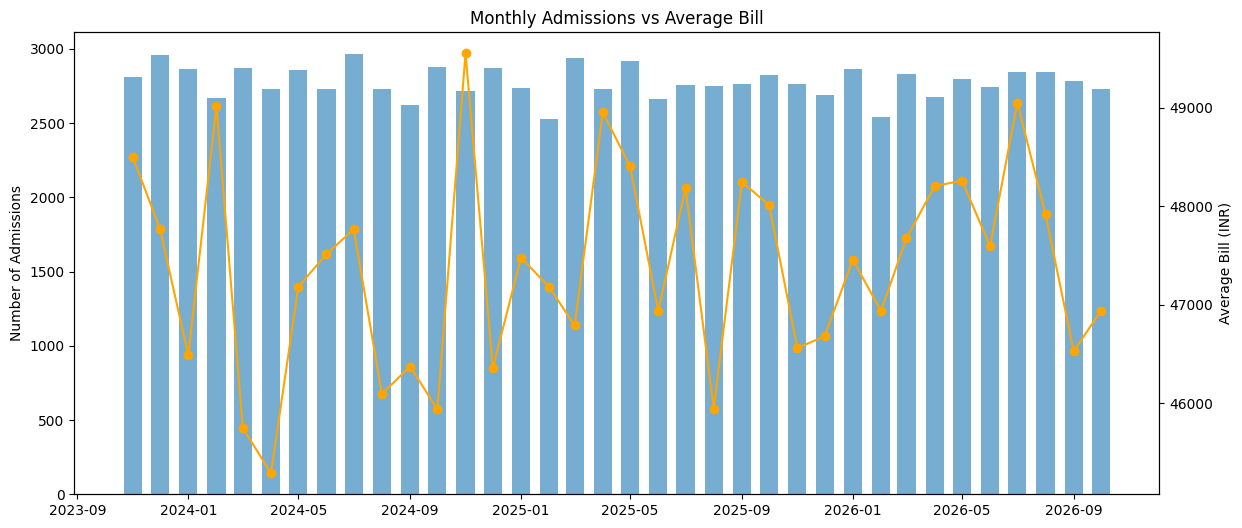

In [119]:
monthly_data = df.groupby(df['admission_date'].dt.to_period('M')).agg(
    admission_count=('patient_id', 'count'),
    avg_bill=('total_bill_inr', 'mean')
)
monthly_data.index = monthly_data.index.to_timestamp()

fig, ax1 = plt.subplots(figsize=(14, 6))

ax1.bar(monthly_data.index, monthly_data['admission_count'], width=20, alpha=0.6)
ax1.set_ylabel('Number of Admissions')

ax2 = ax1.twinx()
ax2.plot(monthly_data.index, monthly_data['avg_bill'], color='orange', marker='o')
ax2.set_ylabel('Average Bill (INR)')

plt.title('Monthly Admissions vs Average Bill')
plt.show()

### Question 35: Multi-Panel Pie Chart Row (Smoking, Alcohol, Allergies)

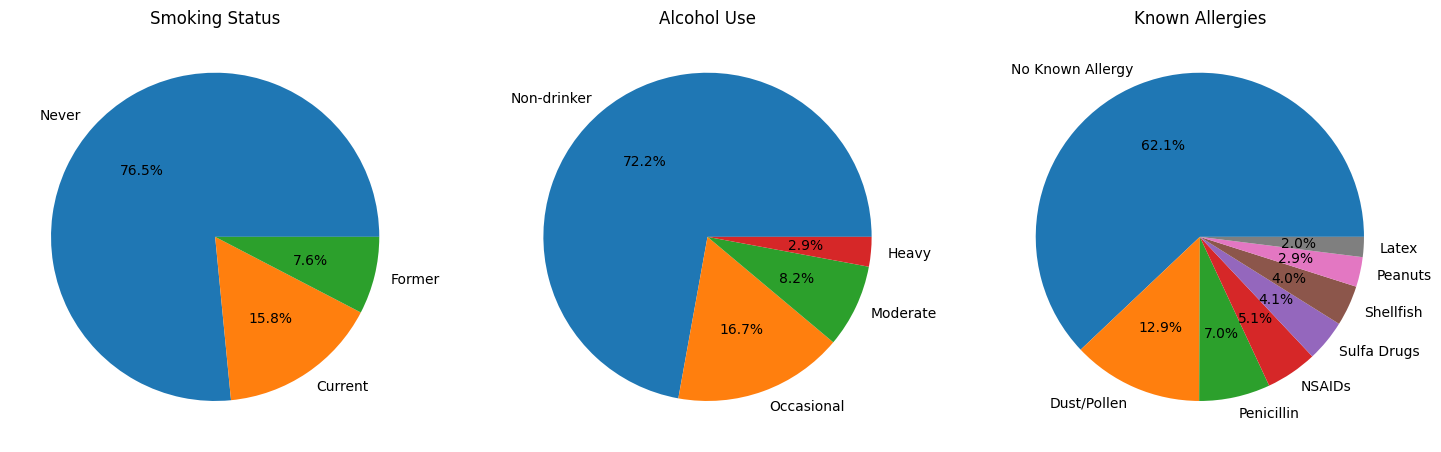

In [120]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

smoke = df['smoking_status'].value_counts()
axes[0].pie(smoke, labels=smoke.index, autopct='%1.1f%%')
axes[0].set_title('Smoking Status')

alcohol = df['alcohol_use'].value_counts()
axes[1].pie(alcohol, labels=alcohol.index, autopct='%1.1f%%')
axes[1].set_title('Alcohol Use')

allergy = df['known_allergy'].value_counts()
axes[2].pie(allergy, labels=allergy.index, autopct='%1.1f%%')
axes[2].set_title('Known Allergies')

plt.show()

### Question 36: Horizontal Stacked Bar Chart (Payment Status by Insurance Provider)

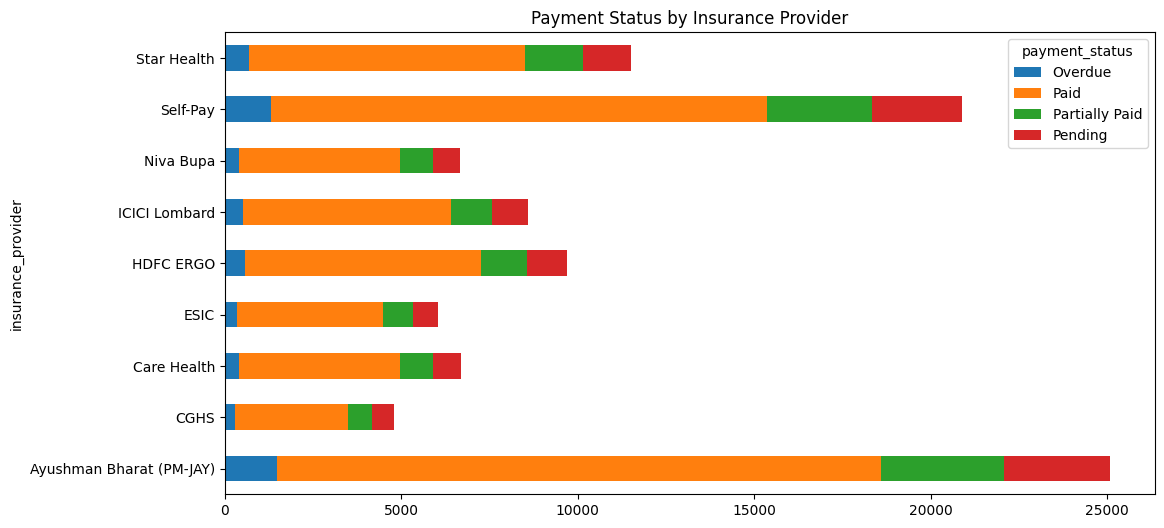

In [121]:
payment_insurance = pd.crosstab(df['insurance_provider'], df['payment_status'])
payment_insurance.plot(kind='barh', stacked=True, figsize=(12, 6))
plt.title('Payment Status by Insurance Provider')
plt.show()

### Question 37: Dual Bar Comparison Chart (Departments: Emergency vs Elective)

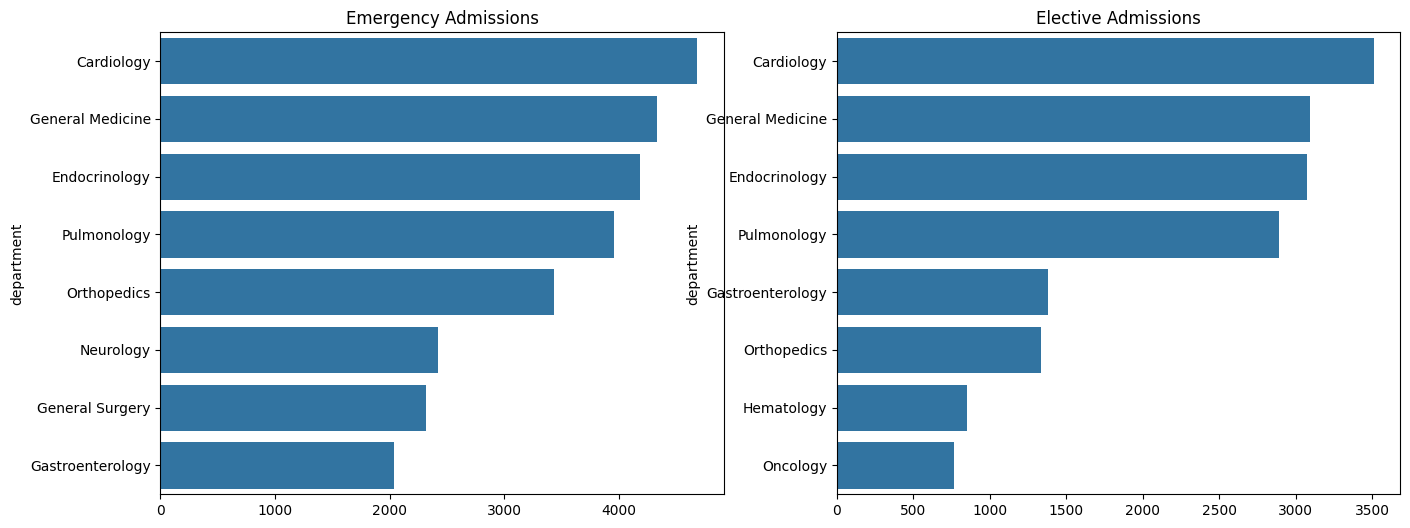

In [122]:
emergency_dept = df[df['admission_type'] == 'Emergency']['department'].value_counts().head(8)
elective_dept = df[df['admission_type'] == 'Elective']['department'].value_counts().head(8)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(x=emergency_dept.values, y=emergency_dept.index, ax=axes[0])
axes[0].set_title('Emergency Admissions')

sns.barplot(x=elective_dept.values, y=elective_dept.index, ax=axes[1])
axes[1].set_title('Elective Admissions')

plt.show()

### Question 38: Age Group Pie Chart

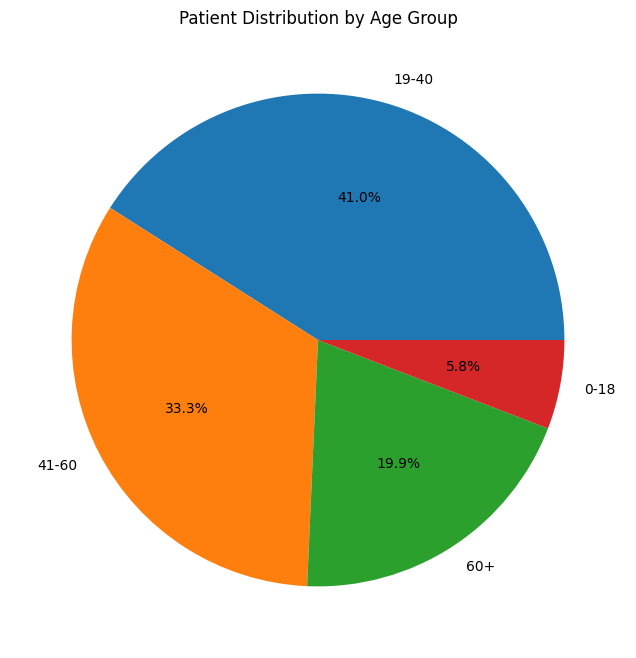

In [123]:
age_group_counts = df['age_group'].value_counts()
plt.figure(figsize=(8, 8))
plt.pie(age_group_counts, labels=age_group_counts.index, autopct='%1.1f%%')
plt.title('Patient Distribution by Age Group')
plt.show()

### Question 39: Horizontal Bar and Pie Comparison (Patient State Distributions)

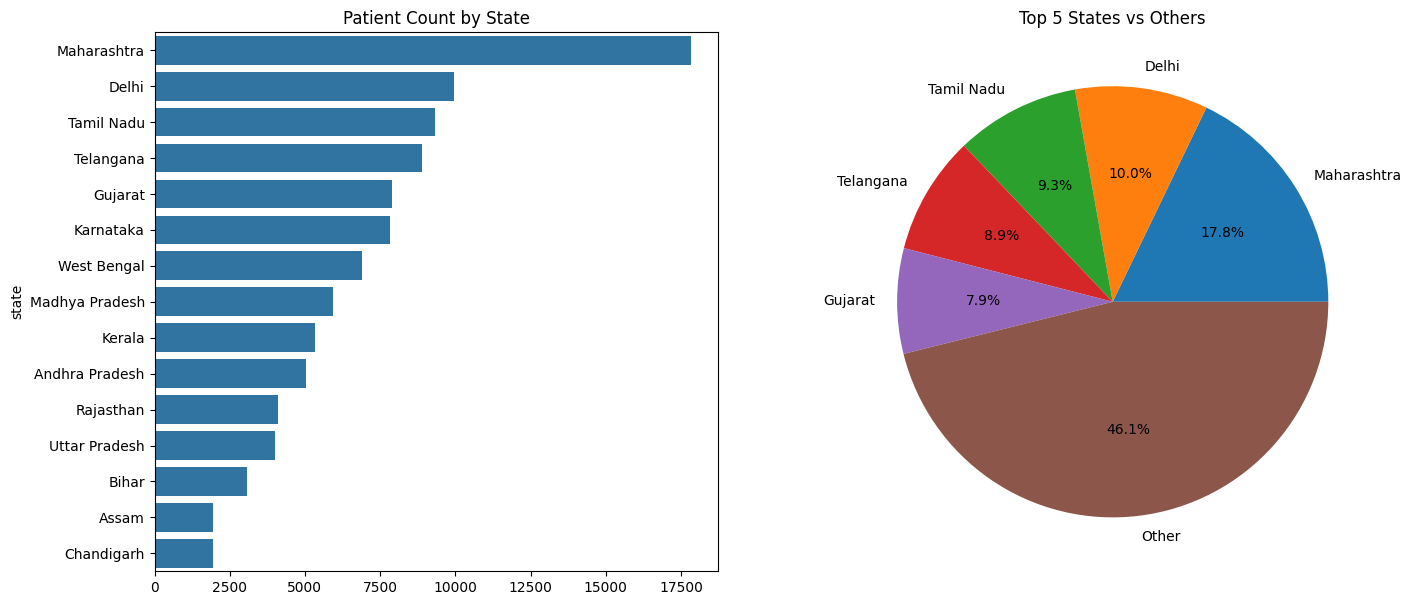

In [124]:
state_counts = df['state'].value_counts()
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

sns.barplot(x=state_counts.values, y=state_counts.index, ax=axes[0])
axes[0].set_title('Patient Count by State')

top_5 = state_counts.head(5)
other_val = state_counts.iloc[5:].sum()
pie_data = pd.concat([top_5, pd.Series({'Other': other_val})])

axes[1].pie(pie_data, labels=pie_data.index, autopct='%1.1f%%')
axes[1].set_title('Top 5 States vs Others')

plt.show()

### Question 40: Three-Panel Grid Comparison (BMI, Risk Score & Categories)

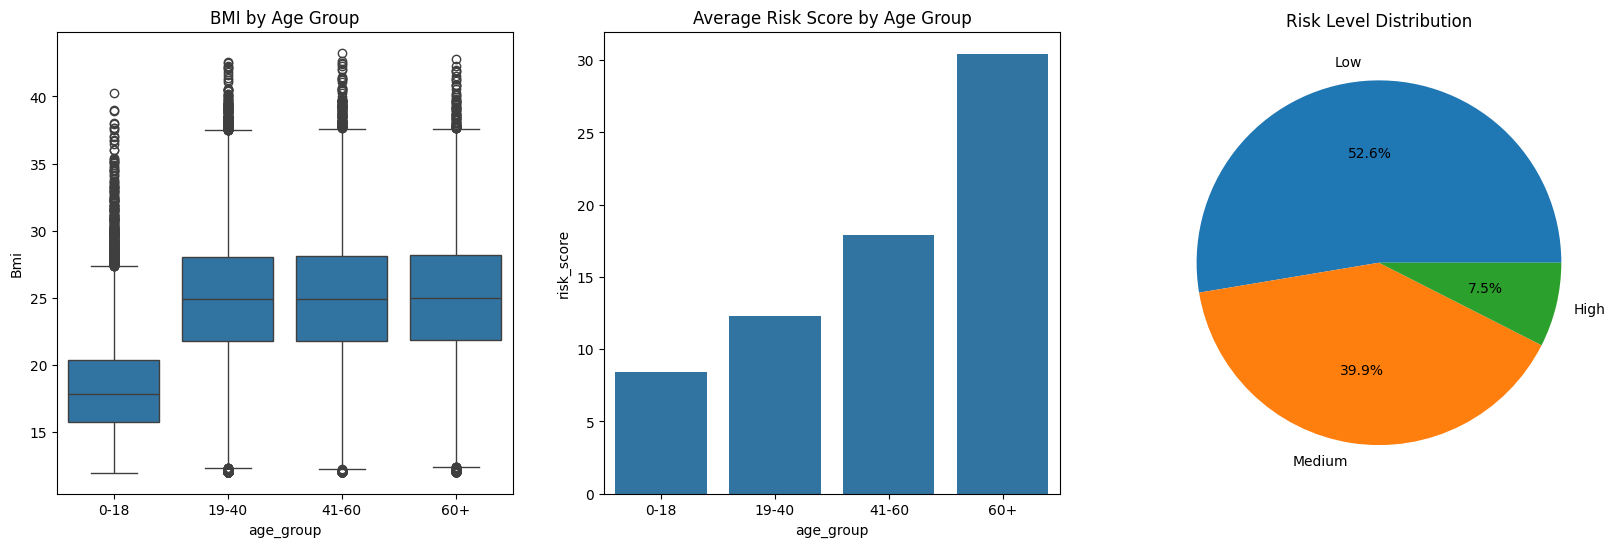

In [125]:
df['risk_category'] = pd.cut(df['risk_score'], bins=[0, 15, 35, 100], labels=['Low', 'Medium', 'High'])
risk_cat_counts = df['risk_category'].value_counts()

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

sns.boxplot(data=df, x='age_group', y='Bmi', ax=axes[0])
axes[0].set_title('BMI by Age Group')

sns.barplot(data=df, x='age_group', y='risk_score', ax=axes[1], errorbar=None)
axes[1].set_title('Average Risk Score by Age Group')

axes[2].pie(risk_cat_counts, labels=risk_cat_counts.index, autopct='%1.1f%%')
axes[2].set_title('Risk Level Distribution')

plt.show()